# 01 — Magnitude of completeness (Mc)

**Question:** above which magnitude does the GOSSIP catalogue record practically every earthquake, and how has that changed since 2005?

**Why it matters:** the seismic network grew a lot after 2005. Below the magnitude of completeness, Mc, some events go undetected, so counting *all* events would partly measure the network rather than the volcano. Counting only events with M ≥ Mc gives a rate that is comparable across the years. We need this for the forecasting targets, for the Gutenberg–Richter analysis, and to reproduce the paper (arXiv 2503.20129), which used M ≥ 0.5.

**Plan for this notebook:**
1. Look at the magnitudes: their precision, their discrete values, and the cumulative magnitude distribution in different periods. *(this step)*
2. One Mc for the whole catalogue (maximum curvature, searched at Md ≥ 0.5), plus the b-value.
3. Mc over time, in moving windows.
4. Cross-check with b-value stability, with bootstrap error bars.
5. Choose the cut and compare the event count with the paper's 11,166.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.completeness import (
    MC_SEARCH_MIN,
    b_value_mle,
    b_stability,
    b_value_over_time,
    bootstrap,
    bin_magnitudes,
    cumulative_counts,
    frequency_magnitude,
    mc_maxc,
    mc_mbs,
    mc_over_time,
)

df = pd.read_parquet("../data/processed/catalogue.parquet")
mags = df[df["has_magnitude"]].copy()
print(f"{len(mags):,} of {len(df):,} events have a magnitude (Md); only these can be used for Mc.")

30,871 of 34,535 events have a magnitude (Md); only these can be used for Mc.


## 1a. Magnitude precision

Md is normally reported to 0.1. But from July 2021 to early September 2023 GOSSIP reports it to 0.01. The table shows the share of magnitudes with two decimals each year.

In [2]:
mags["two_decimals"] = (mags["md"] - bin_magnitudes(mags["md"])).abs() > 1e-6
by_year = mags.groupby(mags["time"].dt.year)["two_decimals"].agg(["sum", "size", "mean"])
by_year.columns = ["two_decimals", "events", "share"]
by_year.loc[2019:2024].round(2)

,two_decimals,events,share
time,,,
2019,0,701,0.00
2020,1,1323,0.00
2021,779,1965,0.40
2022,2792,2806,1.00
2023,3775,5460,0.69
2024,0,6059,0.00


Where we need a common grid (counts per bin), we round every magnitude to the nearest 0.1 with `bin_magnitudes`. The raw `md` column in the processed table stays unchanged.

*To keep in mind:* a change in reported precision may also mean a change in how Md was computed. If so, magnitudes from 2021–2023 could be shifted slightly compared with other years. Steps 3–4 (Mc and b-value over time) would show this as a jump at those dates.

## 1b. Small magnitudes take discrete values

The two-decimal period shows something the rounded years hide: below about Md 1, magnitudes take only a few fixed values. The table lists the values that occur at least 20 times in that period, and the gap to the next one.

In [3]:
two_dec_period = mags[(mags["time"] >= "2021-07-15") & (mags["time"] < "2023-09-01")]
values = two_dec_period["md"].value_counts().sort_index()
values = values[(values >= 20) & (values.index < 1.1)]
pd.DataFrame({
    "events": values,
    "gap_to_next": np.round(np.diff(values.index, append=np.nan), 2),
}).rename_axis("md")

,events,gap_to_next
md,,
-1.11,156,0.35
-0.76,763,0.27
-0.49,1217,0.22
-0.27,1256,0.19
-0.08,1014,0.17
0.09,745,0.14
0.23,536,0.13
0.36,372,0.12
0.48,263,0.10


Duration magnitude is computed from how long the shaking signal lasts, roughly Md = a + b·log₁₀(duration). The values above fit durations measured in **whole seconds**: each extra second raises Md by one step. For short, small events one second is a large relative change, so the steps are big (0.35 at the bottom); for longer events they shrink. In the other years the same values appear, rounded to one decimal (−0.8, −0.5, −0.3, −0.1, 0.1, 0.2, 0.4, …).

**Consequence:** below about Md 0.5 the steps are wider than 0.1. Some 0.1 bins then contain one value and some none, so counts per 0.1 bin jump up and down for reasons unrelated to detection, and the "most common bin" used by the maximum-curvature method is not meaningful there. Above Md 0.5 the steps are 0.1 or smaller and 0.1 bins behave normally.

So we **search for Mc only at Md ≥ 0.5** (`MC_SEARCH_MIN`). We cannot resolve an Mc below 0.5, which is acceptable: the paper used M ≥ 0.5, and the early years will need a cut at least that high.

## 1c. Cumulative magnitude distribution by period

Instead of counts per bin, we plot N(≥M): the number of events with magnitude at least M. This does not depend on how bins line up with the discrete values.

**How to read it:** for a complete catalogue, Gutenberg–Richter says log₁₀ N(≥M) = a − b·M, a straight line on a log scale. Above Mc the curve is straight; below Mc it flattens, because small events are missed. The magnitude where the curve starts to bend away from the straight line is a visual estimate of Mc. Curves for different periods differ in height (different numbers of events), so compare their shapes, not their levels.

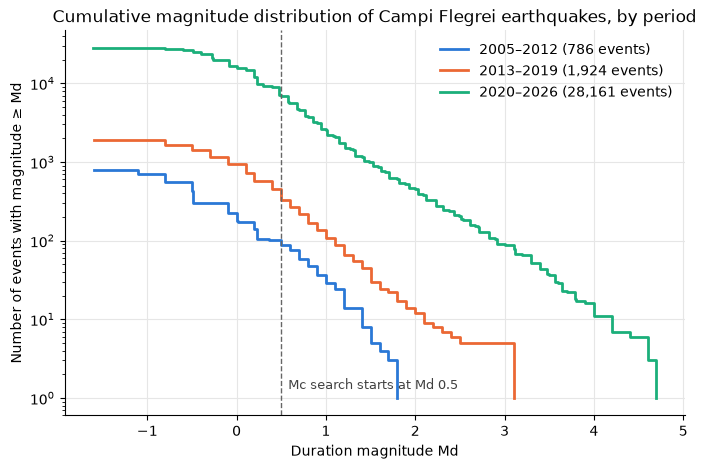

In [4]:
periods = {
    "2005–2012": ("2005-01-01", "2013-01-01"),
    "2013–2019": ("2013-01-01", "2020-01-01"),
    "2020–2026": ("2020-01-01", "2027-01-01"),
}
# Fixed colour per period (categorical palette, slots 1-3).
colours = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, ax = plt.subplots(figsize=(8, 5))
for (label, (start, end)), colour in zip(periods.items(), colours):
    in_period = mags[(mags["time"] >= start) & (mags["time"] < end)]
    n = cumulative_counts(in_period["md"])
    ax.plot(n.index, n.values, drawstyle="steps-post", linewidth=2, color=colour,
            label=f"{label} ({len(in_period):,} events)")

ax.axvline(MC_SEARCH_MIN, color="0.4", linewidth=1, linestyle="--")
ax.annotate(f"Mc search starts at Md {MC_SEARCH_MIN}", (MC_SEARCH_MIN, 1.3),
            textcoords="offset points", xytext=(5, 0), fontsize=9, color="0.25")
ax.set_yscale("log")
ax.set_xlabel("Duration magnitude Md")
ax.set_ylabel("Number of events with magnitude ≥ Md")
ax.set_title("Cumulative magnitude distribution of Campi Flegrei earthquakes, by period")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

**What the plot shows (by eye; steps 2–4 measure it):** for 2013–2019 and 2020–2026, the curves are close to straight lines from about Md 0.5 up to the largest events, and flatten below roughly Md 0.3. For 2005–2012 there are few events, so the curve is noisy, but it also looks roughly straight above about 0.5. So a common Mc near 0.5 looks plausible, which would match the paper's cut. The straight parts also have similar slopes, a first sign that the b-value has not changed much.

## 2. One Mc for the whole catalogue, and the b-value

**Maximum curvature (MAXC)** takes Mc as the most common 0.1 magnitude bin: below it, counts fall because events are missed; above it, they fall because large events are rarer. We only search at Md ≥ 0.5 (section 1b).

In [5]:
counts = frequency_magnitude(mags["md"])
counts.loc[0.5:1.5].to_frame().T

md_bin,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5
count,1475,1155,922,661,743,442,434,281,284,197,140


Two things show up in these counts:

- **The counts fall from 0.5 upward**, so within the search range the most common bin is 0.5 itself. MAXC therefore returns the bottom of the search range. That only tells us **Mc ≤ 0.5**: the true peak may be lower, where we chose not to look.
- **Bins are still a little lumpy above 0.5:** 0.9 has more events than 0.8, and 1.3 more than 1.2. The discrete Md values are now a bit less than 0.1 apart, so some bins catch two values and others one. This doesn't affect the b-value below, which depends only on the mean magnitude.

Woessner & Wiemer (2005) recommend adding +0.2 to MAXC, because it tends to underestimate Mc. That correction only makes sense when the peak is actually found; here the 0.5 is set by our search floor, so we don't apply it.

The same check by period:

In [6]:
rows = {}
for label, (start, end) in periods.items():
    in_period = mags.loc[(mags["time"] >= start) & (mags["time"] < end), "md"]
    rows[label] = {"events": len(in_period), "mc_maxc": mc_maxc(in_period)}
rows["all years"] = {"events": len(mags), "mc_maxc": mc_maxc(mags["md"])}
pd.DataFrame(rows).T.astype({"events": int})

,events,mc_maxc
2005–2012,786,0.6
2013–2019,1924,0.5
2020–2026,28161,0.5
all years,30871,0.5


For 2013–2019, 2020–2026 and all years together, MAXC sits at the floor of 0.5. For 2005–2012 it returns 0.6, but that rests on 17 events in the 0.6 bin against 12 in the 0.5 bin: well within random noise. Steps 3–4 test whether the early years really need a higher cut.

**b-value.** The Gutenberg–Richter law says log₁₀ N(≥M) = a − b·M: each step of one magnitude unit has about 10^b times fewer events. Volcanic areas often have b ≥ 1. We estimate b by maximum likelihood (Aki 1965), with Utsu's correction for 0.1 bins:

b = log₁₀(e) / (mean M − (Mc − 0.05))

using only events with M ≥ Mc. The uncertainty is from Shi & Bolt (1982). We use Mc = 0.5.

In [7]:
mc = MC_SEARCH_MIN
rows = {}
for label, (start, end) in {**periods, "all years": ("2005-01-01", "2027-01-01")}.items():
    in_period = mags.loc[(mags["time"] >= start) & (mags["time"] < end), "md"]
    b, b_sigma, n = b_value_mle(in_period, mc)
    rows[label] = {"events_M_ge_Mc": n, "b": round(b, 2), "b_sigma": round(b_sigma, 2)}
pd.DataFrame(rows).T.astype({"events_M_ge_Mc": int})

,events_M_ge_Mc,b,b_sigma
2005–2012,88,1.06,0.09
2013–2019,332,0.98,0.05
2020–2026,7216,0.84,0.01
all years,7636,0.85,0.01


The plot checks the fit by eye: the cumulative counts for all years (0.1 bins) against the Gutenberg–Richter line with this b-value, anchored at the number of events with M ≥ 0.5.

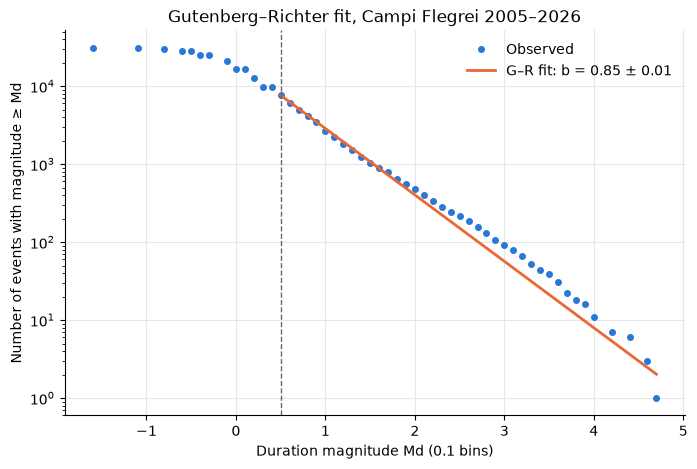

In [8]:
binned = bin_magnitudes(mags["md"])
n_cum = cumulative_counts(binned)
b, b_sigma, n = b_value_mle(mags["md"], mc)
fit_m = np.linspace(mc, binned.max(), 50)
fit_n = n * 10 ** (-b * (fit_m - mc))  # log10 N = log10 n - b (M - Mc)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(n_cum.index, n_cum.values, marker="o", markersize=4, linewidth=0, color="#2a78d6",
        label="Observed")
ax.plot(fit_m, fit_n, linewidth=2, color="#eb6834",
        label=f"G–R fit: b = {b:.2f} ± {b_sigma:.2f}")
ax.axvline(mc, color="0.4", linewidth=1, linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Duration magnitude Md (0.1 bins)")
ax.set_ylabel("Number of events with magnitude ≥ Md")
ax.set_title("Gutenberg–Richter fit, Campi Flegrei 2005–2026")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

**What step 2 tells us:**

- **MAXC cannot pin down Mc here.** Within the range we can trust (Md ≥ 0.5), counts fall from the first bin, so MAXC only says Mc ≤ 0.5 for the catalogue as a whole and for the later periods. It is consistent with using Mc = 0.5, like the paper, but it is not a measurement of it. The early period (MAXC 0.6) rests on very few events.
- **The b-value seems to fall over time:** 1.06 ± 0.09 (2005–2012), 0.98 ± 0.05 (2013–2019), 0.84 ± 0.01 (2020–2026). A falling b-value means relatively more larger events, and in volcanoes it is often read as rising stress. But there are other explanations to rule out first: if the early years are incomplete above 0.5, that would bias their b *down*, not up, so it doesn't explain the trend; a change in how Md is computed (section 1a: precision changed in 2021–2023) could. Step 3 (b and Mc in moving windows) will show whether the change is gradual or a jump at a date when the method changed.
- **The straight line fits from 0.5 to about 2, but above about Md 2 the observed counts lie above it**: there are more large events than one b-value predicts. Two likely reasons: (1) pooling periods with different b-values and very different event numbers produces a curve that bends this way; (2) the relation between duration magnitude and true size may not be linear at larger magnitudes. Since our M ≥ 3 target lives in this range, this matters later: a single Gutenberg–Richter b from small events would underpredict M ≥ 3 events.

## 3. Mc and b-value over time

Fixed periods hide when things change. Here we slide a window along the catalogue in time order and recompute in each window:

- **Mc (MAXC):** windows of 1,000 events with a magnitude, moving 250 events at a time.
- **b-value:** windows of 200 events with M ≥ 0.5, moving 50 at a time. 200 is about the fewest that gives a usable b (uncertainty ≈ ±0.07).

The windows are defined by *number of events*, not by time. So in quiet years one window spans several years, and during a swarm only days. Each point is plotted at the window's median event time. Neighbouring windows overlap, so neighbouring points are not independent.

The shaded band marks July 2021 – September 2023, when Md was reported to 0.01 (section 1a). If the way Md was computed changed then, Mc or b would jump at the edges of the band.

In [9]:
mc_t = mc_over_time(mags)
b_t = b_value_over_time(mags)
print(f"{len(mc_t)} windows for Mc, {len(b_t)} windows for b")
print("Mc (MAXC) per window:", mc_t["mc_maxc"].value_counts().sort_index().to_dict())

120 windows for Mc, 149 windows for b
Mc (MAXC) per window: {0.5: 105, 0.6: 13, 0.7: 2}


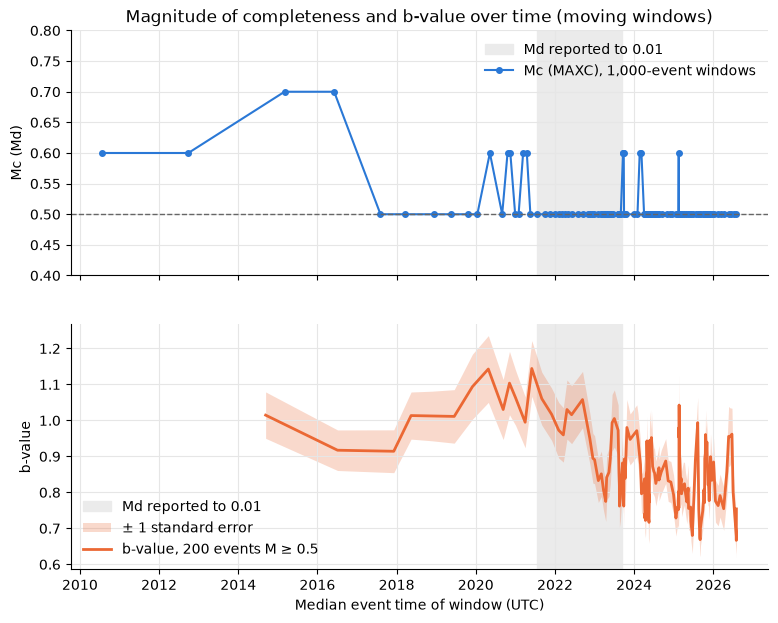

In [10]:
precision_change = (pd.Timestamp("2021-07-15", tz="UTC"), pd.Timestamp("2023-09-08", tz="UTC"))

fig, (ax_mc, ax_b) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for ax in (ax_mc, ax_b):
    ax.axvspan(*precision_change, color="0.92", label="Md reported to 0.01")
    ax.grid(True, which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

ax_mc.plot(mc_t["mid"], mc_t["mc_maxc"], marker="o", markersize=4, linewidth=1.5,
           color="#2a78d6", label="Mc (MAXC), 1,000-event windows")
ax_mc.axhline(MC_SEARCH_MIN, color="0.4", linewidth=1, linestyle="--")
ax_mc.set_ylabel("Mc (Md)")
ax_mc.set_ylim(0.4, 0.8)
ax_mc.set_title("Magnitude of completeness and b-value over time (moving windows)")
ax_mc.legend(frameon=False, loc="upper right")

ax_b.fill_between(b_t["mid"], b_t["b"] - b_t["b_sigma"], b_t["b"] + b_t["b_sigma"],
                  color="#eb6834", alpha=0.25, linewidth=0, label="± 1 standard error")
ax_b.plot(b_t["mid"], b_t["b"], linewidth=2, color="#eb6834", label="b-value, 200 events M ≥ 0.5")
ax_b.set_ylabel("b-value")
ax_b.set_xlabel("Median event time of window (UTC)")
ax_b.legend(frameon=False, loc="lower left")
plt.show()

In [11]:
# The b-value by calendar year of the window's median time.
b_t.groupby(b_t["mid"].dt.year)["b"].agg(["size", "median", "min", "max"]).round(2)

,size,median,min,max
mid,,,,
2014,1,1.01,1.01,1.01
2016,1,0.92,0.92,0.92
2017,1,0.91,0.91,0.91
2018,2,1.01,1.01,1.01
2019,2,1.05,1.01,1.09
2020,3,1.10,1.03,1.14
2021,5,1.06,0.99,1.14
2022,7,0.97,0.89,1.06
2023,24,0.85,0.76,1.01


**What step 3 shows:**

- **Mc before about 2017 may be above 0.5.** The first four Mc windows (each 1,000 events, together spanning 2005–2018) give 0.6–0.7. These rest on few events per bin, so step 4 needs to test them. If they hold, a cut at 0.5 would miss some events in the early years, and their b-values here would be biased *low*.
- **From 2017 on, Mc is at or below 0.5**, with short rises to 0.6 in 2020–2021 and during the intense swarms (September 2023, early 2024, February 2025). During a swarm, events overlap and small ones are missed: the short-term incompleteness mentioned in the plan. A 0.5 cut is slightly optimistic for those few days.
- **The b-value falls during 2022–2023, from about 1.0–1.1 to about 0.8, and stays there.** The drop happens gradually *inside* the shaded period, not as a jump at its edges (July 2021, September 2023). That argues against a one-off change in how Md was computed, though a gradual change in processing can't be ruled out from the catalogue alone. Combined with the possible low bias in the early windows, the decline in b is, if anything, understated here.
- After 2023 b varies a lot (about 0.7–1.0) from window to window, because 200-event windows during swarms cover only days.

## 4. Cross-check: b-value stability (MBS) and bootstrap error bars

Step 3 suggested Mc of 0.6–0.7 before about 2017. Here we test that with a second method and with error bars.

**b-value stability (MBS; Cao & Gao 2002, Woessner & Wiemer 2005).** If the trial Mc is too low, missing small events pull b down. Once the trial Mc is above the true Mc, b stops changing (apart from noise). So we compute b for trial Mc = 0.5, 0.6, …, and take Mc as the lowest value where b is within its uncertainty of b averaged over the next 0.5 magnitude units.

We compare three periods, split where step 3 saw Mc settle at 0.5 (2017) and where the b-value fell (2022): 2005–2016 (the focus), 2017–2021 and 2022–2026.

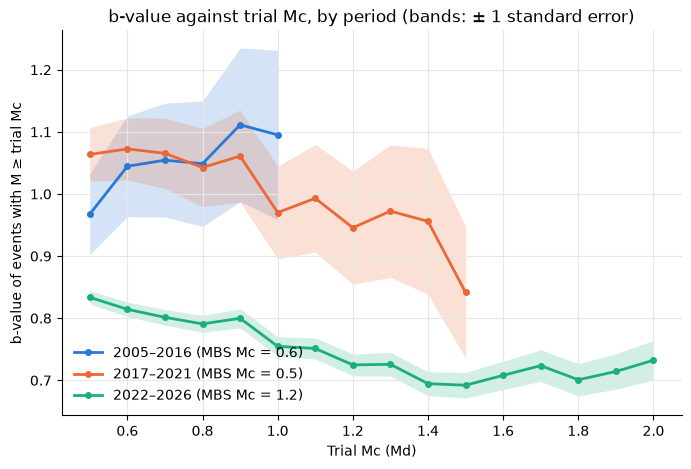

In [12]:
mbs_periods = {
    "2005–2016": ("2005-01-01", "2017-01-01"),
    "2017–2021": ("2017-01-01", "2022-01-01"),
    "2022–2026": ("2022-01-01", "2027-01-01"),
}
md_by_period = {
    label: mags.loc[(mags["time"] >= start) & (mags["time"] < end), "md"]
    for label, (start, end) in mbs_periods.items()
}

fig, ax = plt.subplots(figsize=(8, 5))
for (label, md_values), colour in zip(md_by_period.items(), colours):
    table = b_stability(md_values, max_mag=2.0)
    table = table[table["n"] >= 50]  # too few events above this: b is noise
    ax.fill_between(table.index, table["b"] - table["b_sigma"], table["b"] + table["b_sigma"],
                    color=colour, alpha=0.2, linewidth=0)
    ax.plot(table.index, table["b"], marker="o", markersize=4, linewidth=2, color=colour,
            label=f"{label} (MBS Mc = {mc_mbs(md_values):.1f})")
ax.set_xlabel("Trial Mc (Md)")
ax.set_ylabel("b-value of events with M ≥ trial Mc")
ax.set_title("b-value against trial Mc, by period (bands: ± 1 standard error)")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
plt.show()

In [13]:
# The numbers behind the 2005–2016 curve.
b_stability(md_by_period["2005–2016"], max_mag=1.5).loc[:1.0].round(3)

,b,b_sigma,n,b_ave
mc,,,,
0.5,0.968,0.065,174,1.054
0.6,1.045,0.081,149,1.089
0.7,1.054,0.092,118,1.072
0.8,1.049,0.101,92,1.045
0.9,1.111,0.124,76,1.059
1.0,1.095,0.136,58,1.077


**Bootstrap.** To see how much these Mc values could change by chance, we resample the events of each period 500 times (with replacement, fixed seed) and recompute Mc with both methods. The table shows the share of resamples giving each Mc. We also split 2005–2016 into 2005–2012 and 2013–2016.

In [14]:
boot_periods = {"2005–2012": ("2005-01-01", "2013-01-01"),
                "2013–2016": ("2013-01-01", "2017-01-01"),
                **mbs_periods}
rows = {}
for label, (start, end) in boot_periods.items():
    md_values = mags.loc[(mags["time"] >= start) & (mags["time"] < end), "md"]
    for method, func in [("MAXC", mc_maxc), ("MBS", mc_mbs)]:
        draws = pd.Series(bootstrap(md_values, func, n_boot=500, seed=42))
        shares = draws.value_counts(normalize=True, dropna=False)
        rows[(label, method)] = shares.rename(index=lambda v: "no result" if pd.isna(v) else f"{v:.1f}")
boot = pd.DataFrame(rows).T.fillna(0)
boot = boot[sorted(boot.columns, key=lambda c: (c == "no result", c))]
(boot * 100).round(0).astype(int).rename_axis(["period", "method"])

0.5  0.6  0.7  0.8  0.9  1.0  1.1  1.2  1.3  1.4  1.5  \
period    method                                                          
2005–2012 MAXC     15   68    9    3    1    0    4    0    0    0    0   
          MBS       3   10    4    7    0    0    0    0    0    0    0   
2013–2016 MAXC     27   34   33    0    6    0    0    0    0    0    0   
          MBS      83   12    3    0    0    0    0    0    0    0    0   
2005–2016 MAXC     14   64   20    1    0    0    1    0    0    0    0   
          MBS      33   37   17    9    3    0    1    0    0    0    0   
2017–2021 MAXC     91    8    0    0    0    0    0    0    0    0    0   
          MBS      77    7    3    5    1    5    0    1    0    0    0   
2022–2026 MAXC    100    0    0    0    0    0    0    0    0    0    0   
          MBS       0    0    0    0    0    2    1   63    6   27    1   

                  no result  
period    method             
2005–2012 MAXC            0  
          MBS            76  
2013–2016 MAXC            0  
          MBS             1  
2005–2016 MAXC            0  
          MBS             0  
2017–2021 MAXC            0  
          MBS             0  
2022–2026 MAXC            0  
          MBS             1

**Is the 2022–2026 MBS value of 1.2 real?** For 2022–2026, b falls steadily as the trial Mc rises, from 0.83 at 0.5 to about 0.70 at 1.4, and only then levels off. MBS reads that as incompleteness up to 1.2, but MAXC puts Mc at 0.5 in every resample. One way to tell them apart: the same drift appears within single years, including the quiet first eight months of 2026, which has no big swarm to hide small events.

In [15]:
single_years = {
    "2022": ("2022-01-01", "2023-01-01"),
    "2024": ("2024-01-01", "2025-01-01"),
    "2026 Jan–Aug (quiet)": ("2026-01-01", "2026-09-01"),
}
rows = {}
for label, (start, end) in single_years.items():
    table = b_stability(mags.loc[(mags["time"] >= start) & (mags["time"] < end), "md"], max_mag=1.4)
    rows[label] = {"events_M_ge_0.5": int(table.loc[0.5, "n"]),
                   **{f"b at Mc {mc:.1f}": round(table.loc[mc, "b"], 2) for mc in [0.5, 0.8, 1.1, 1.4]}}
pd.DataFrame(rows).T.astype({"events_M_ge_0.5": int})

,events_M_ge_0.5,b at Mc 0.5,b at Mc 0.8,b at Mc 1.1,b at Mc 1.4
2022,379,0.96,0.94,0.82,0.75
2024,1775,0.84,0.83,0.77,0.67
2026 Jan–Aug (quiet),727,0.79,0.72,0.67,0.64


**What step 4 shows:**

- **2005–2016: Mc ≈ 0.6, not 0.5.** b jumps from 0.97 at Mc 0.5 to 1.05 at 0.6 and then stays flat: the classic sign that events are missing at 0.5. Both methods give 0.6. In the bootstrap, MAXC gives 0.6 or higher in 86% of resamples and MBS in 67%; 0.7 is also possible (20% and 17%). Split further, 2005–2012 has too few events for MBS (no result in 76% of resamples), and 2013–2016 is borderline between 0.5 and 0.7.
- **2017–2021: Mc = 0.5** (or lower). b is flat from 0.5 to about 0.9, and both methods give 0.5 in most resamples (MAXC 91%, MBS 77%).
- **2022–2026: MAXC says 0.5; the MBS value of 1.2 is not a believable Mc.** With about 25,000 events the uncertainty of b is tiny (±0.01), so any curvature in the magnitude distribution fails the stability test. The drift appears in single years too, quiet periods included, so it is unlikely to be swarm-related incompleteness. More likely the magnitude distribution simply isn't a single straight Gutenberg–Richter line: for these years b is about 0.8 for small events and about 0.7 for M ≳ 1.4 (the bend seen in step 2). This matters for the M ≥ 3 target: b estimated from M ≥ 0.5 overestimates how fast large events become rare.

So the evidence points to **Mc ≈ 0.6 (perhaps 0.7) before 2017, and 0.5 from 2017**. Step 5 chooses the cut.